# **Procesamiento de Modelos Digitales de Elevación (DEM) y Generación de Curvas de Nivel**
Antes de comenzar, te invito a revisar el [Apunte Teórico](https://colab.research.google.com/drive/1fipmTXLxFRu6cGP6h_zQ0AVUZiePvd0S?usp=sharing) para una mejor comprensión de los conceptos y procedimientos detrás de este flujo de trabajo.

Este notebook presenta un flujo de trabajo completo para la descarga, reproyección, suavizado y extracción de curvas de nivel utilizando datos de **ALOS PALSAR** para la Región del Ñuble, Chile. El flujo considera tres escalas: Regional, Comunal y Nivel Predial.

## **Parámetros Globales de Configuración**

Centralización de constantes y configuraciones del flujo de procesamiento.

In [1]:
# ==============================================================================
# RUTAS DE ENTRADA Y SERVICIOS
# ==============================================================================
# DEM Alos Palsar Región del Ñuble (IDE Geoportal)
URL_DESCARGA_DEM = "https://geoportal.cl/geoportal/catalog/download/aff5914a-6d62-30a6-861c-c1e6877f946d"

# Límite comunal (GeoJSON)
RUTA_GEOJSON_COMUNA = "/content/drive/MyDrive/data/chl_nuble_chillan_viejo.geojson"

# Límite del predio (KML)
RUTA_KML_PREDIO = "/content/drive/MyDrive/data/limites_predio_ejemplo.kml"

# ==============================================================================
# 2. PARÁMETROS DE PROCESAMIENTO GENERAL
# ==============================================================================
# Resolución espacial de salida para los análisis reproyectados (metros)
RES_M = 12.5

# Factor de submuestreo para la vista previa regional rápida
FACTOR_REDUCCION_VISTA = 20

# ==============================================================================
# 3. ESCALA COMUNAL (CHILLÁN VIEJO)
# ==============================================================================
# Intervalo de curvas de nivel para el análisis comunal (metros)
INTERVALO_COMUNA_M = 20

# ==============================================================================
# 4. ESCALA PREDIAL
# ==============================================================================
# Margen de seguridad alrededor del predio para el clip inicial (metros)
BUFFER_PREDIO_M = 150

# Grado de suavizado espacial Gaussiano (metros)
SIGMA_SUAVIZADO_M = 20

# Intervalo entre curvas de nivel del predio (metros)
INTERVALO_PREDIO_M = 1

# Intervalo para resaltar curvas maestras en el predio (metros)
INTERVALO_MAESTRAS_PREDIO_M = 2

In [2]:
import os
from pathlib import Path

# Determinar el entorno de ejecución de forma sencilla
if 'COLAB_RELEASE_TAG' in os.environ:
    environment = 'colab_enterprise' if os.environ.get('VERTEX_PRODUCT') == 'COLAB_ENTERPRISE' else 'colab'
else:
    environment = 'local'

# Configuración de Google Drive y carpetas
use_google_drive = True

if environment == 'colab' and use_google_drive:
    from google.colab import drive
    drive.mount('/content/drive')
    base_path = Path('/content/drive/MyDrive')
else:
    base_path = Path('.')

# Definir y crear las carpetas de datos y salida de forma directa
CARPETA_DATOS = base_path / 'data'
CARPETA_SALIDA = base_path / 'output'

CARPETA_DATOS.mkdir(parents=True, exist_ok=True)
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)

print(f'Entorno: {environment}')
print(f'Carpeta de datos: {CARPETA_DATOS}')
print(f'Carpeta de salida: {CARPETA_SALIDA}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorno: colab
Carpeta de datos: /content/drive/MyDrive/data
Carpeta de salida: /content/drive/MyDrive/output


## 1. Configuración del Entorno e Instalación de Dependencias

En esta sección se identifican las variables de entorno para determinar si la ejecución es local o en Google Colab, se monta Google Drive para el almacenamiento persistente de los resultados y se configuran las carpetas de entrada y salida.

In [3]:
if environment == 'colab':
    !apt-get update -qq && apt-get install -y -qq gdal-bin libgdal-dev
    %pip install -q requests rasterio matplotlib numpy tqdm rioxarray geopandas contextily scipy

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


### Instalación de Librerías Geoespaciales

Instalamos las herramientas de sistema como `GDAL` y las librerías clave de Python para el análisis ráster y vectorial (`rasterio`, `rioxarray`, `geopandas`, `contextily`, etc.).

In [4]:
import re
import zipfile
import numpy as np
import requests
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import rioxarray as rxr
import geopandas as gpd
import subprocess
import contextily as cx
import scipy.ndimage as ndi
import matplotlib.patheffects as pe

## 2. Descarga y Extracción del DEM

Definimos la URL del Geoportal para obtener el DEM de la Región del Ñuble y creamos funciones robustas para:
* Detectar el tipo de archivo analizando sus *Magic Numbers* (primeros bytes).
* Descargar el archivo con soporte de reintentos y visualización de progreso mediante `tqdm`.

In [5]:
def detectar_extension(ruta):
    """Detecta el tipo de archivo mediante sus primeros bytes (Magic Numbers)."""
    with open(ruta, "rb") as f:
        inicio = f.read(16)
    if inicio.startswith(b"PK"):
        return ".zip"
    if inicio[4:8] == b"jP  " or inicio.startswith(b"\x00\x00\x00\x0cjp2"):
        return ".jp2"
    if inicio[:4] in (b"II*\x00", b"MM\x00*"):
        return ".tif"
    if inicio.lstrip().lower().startswith((b"<!doctype", b"<html")):
        return ".html"
    return ""

def descargar_dem(url, carpeta_destino, nombre=None):
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) GoogleColab/1.0"}
    with requests.Session() as s:
        s.headers.update(headers)
        with s.get(url, stream=True, timeout=120, allow_redirects=True) as r:
            r.raise_for_status()
            print("Content-Type del servidor:", r.headers.get("Content-Type"))

            if nombre is None:
                cd = r.headers.get("Content-Disposition", "")
                m = re.search(r'filename\*?=(?:UTF-8\'\')?"?([^";]+)"?', cd)
                nombre = m.group(1) if m else "dem_biobio_descarga"

            destino = carpeta_destino / nombre
            total = int(r.headers.get("Content-Length", 0)) or None

            with open(destino, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=nombre) as barra:
                for chunk in r.iter_content(chunk_size=2 * 1024 * 1024):
                    f.write(chunk)
                    barra.update(len(chunk))

    if destino.suffix == "":
        ext = detectar_extension(destino)
        destino = destino.rename(destino.with_suffix(ext))
    return destino


In [6]:
# Ejecutar descarga a la carpeta configurada (Google Drive o Local) utilizando la constante centralizada
archivo = descargar_dem(URL_DESCARGA_DEM, CARPETA_DATOS)
print(f"✔ Archivo recibido: {archivo.name} ({archivo.stat().st_size / 1e6:.1f} MB)")

if archivo.suffix == "..html":
    raise RuntimeError(
        "El servidor del Geoportal devolvió un HTML en vez del DEM. "
        "Descarga el archivo manualmente y colócalo en: "
        f"{CARPETA_DATOS}"
    )

Content-Type del servidor: application/x-rar


DEM Alos Palsar Region del Nuble.rar:   0%|          | 0.00/18.7M [00:00<?, ?B/s]

✔ Archivo recibido: DEM Alos Palsar Region del Nuble.rar (18.7 MB)


### Descompresión del Archivo Descargado

Dependiendo de si el servidor entregó un archivo `.zip` o `.rar`, se procede con su descompresión automatizada para extraer el archivo ráster en formato `.jp2` (JPEG 2000).

In [7]:
if archivo.suffix == ".zip":
    print("Descomprimiendo archivo ZIP...")
    with zipfile.ZipFile(archivo) as z:
        z.extractall(CARPETA_DATOS)
        print("Archivos extraídos correctamente desde ZIP.")
elif archivo.suffix == ".rar":
    print("Descomprimiendo archivo RAR...")
    # Usamos la herramienta nativa 'unrar' de Colab para extraer el contenido en la carpeta de datos
    resultado = subprocess.run(["unrar", "x", "-o+", str(archivo), str(CARPETA_DATOS)], capture_output=True, text=True)
    if resultado.returncode == 0:
        print("Archivos extraídos correctamente desde RAR.")
    else:
        print("Error al descomprimir con unrar:", resultado.stderr)

EXTENSIONES_RASTER = {".jp2", ".tif", ".tiff", ".img"}
rasters = [p for p in CARPETA_DATOS.rglob("*") if p.suffix.lower() in EXTENSIONES_RASTER]

if not rasters:
    raise FileNotFoundError("No se encontró ningún archivo ráster compatible (.jp2, .tif, .img) en la carpeta.")
else:
    print(f"¡Éxito! Se encontraron {len(rasters)} archivos ráster compatibles:")
    for r in rasters:
        print(f" - {r.relative_to(CARPETA_DATOS)}")


RUTA_DEM = rasters[0]
print(f"✔ Raster listo para análisis: {RUTA_DEM.name}")

Descomprimiendo archivo RAR...
Archivos extraídos correctamente desde RAR.
¡Éxito! Se encontraron 1 archivos ráster compatibles:
 - Ñuble/REGION_NUBLE_1.jp2
✔ Raster listo para análisis: REGION_NUBLE_1.jp2


In [8]:
with rasterio.open(RUTA_DEM) as src:
    dem_crs, dem_bounds, res = src.crs, src.bounds, src.res
    lat_media = (src.bounds.top + src.bounds.bottom) / 2
    print("\n--- METADATOS DEL DEM ---")
    print("Driver     :", src.driver)
    print("CRS        :", src.crs)
    print("Dimensiones:", src.width, "x", src.height)
    print("Tipo / NoData:", src.dtypes[0], "/", src.nodata)
    if src.crs.is_geographic:
        m_ns = res[1] * 111_320
        m_eo = res[0] * 111_320 * np.cos(np.radians(lat_media))
        print(f"Resolución : {res[0]:.6f}° ≈ {m_ns:.1f} m (N-S) x {m_eo:.1f} m (E-O)")
    else:
        print("Resolución :", res, "m")


--- METADATOS DEL DEM ---
Driver     : JP2OpenJPEG
CRS        : EPSG:5360
Dimensiones: 18547 x 12783
Tipo / NoData: uint16 / 0.0
Resolución : 0.000116° ≈ 12.9 m (N-S) x 10.3 m (E-O)


## 3. Exploración Inicial del Ráster (DEM Regional)

Visualizamos un submuestreo del DEM regional (reducido por un factor de 20 para optimizar el rendimiento de renderizado) con el fin de verificar la cobertura, el rango de elevaciones y la calidad de los datos originales.

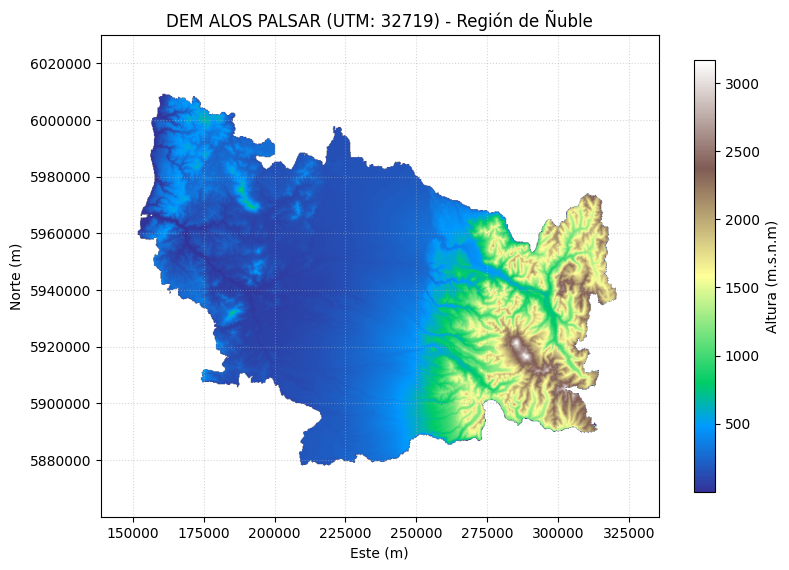

In [9]:
import rioxarray as rxr
import geopandas as gpd
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box

# 1. Abrimos el DEM usando rioxarray
xds_reg = rxr.open_rasterio(RUTA_DEM, masked=True).squeeze(drop=True)

# 2. Estimamos el CRS UTM óptimo a partir de los límites geográficos
# Creamos una geometría de caja (box) directamente y obtenemos su centroide
bounds_geom = gpd.GeoSeries(
    [box(dem_bounds.left, dem_bounds.bottom, dem_bounds.right, dem_bounds.top).centroid],
    crs=dem_crs
)
utm_crs = bounds_geom.estimate_utm_crs()

# 3. Calculamos las dimensiones reducidas para la vista previa
with rasterio.open(RUTA_DEM) as src:
    forma_vista = (src.height // FACTOR_REDUCCION_VISTA, src.width // FACTOR_REDUCCION_VISTA)

# 4. Reproyectamos el DEM al CRS UTM óptimo con el factor de reducción
dem_vista_utm = xds_reg.rio.reproject(
    utm_crs,
    shape=forma_vista,
    resampling=Resampling.average
)

# 5. Obtenemos los límites en coordenadas UTM
ext_utm = dem_vista_utm.rio.bounds()

# 6. Graficar el DEM en coordenadas UTM
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(
    dem_vista_utm.values,
    cmap="terrain",
    extent=(ext_utm[0], ext_utm[2], ext_utm[1], ext_utm[3]),
    origin="upper"
)

fig.colorbar(im, ax=ax, label="Altura (m.s.n.m)", shrink=0.7)
ax.set_title(f"DEM ALOS PALSAR (UTM: {utm_crs.to_epsg()}) - Región de Ñuble")
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")
ax.ticklabel_format(useOffset=False, style="plain")
ax.grid(True, linestyle=":", alpha=0.5)
plt.show()

## 4. Procesamiento a Escala Comunal

En esta etapa realizamos las siguientes operaciones espaciales:
1. Cargamos el límite de la comuna en formato GeoJSON.
2. Determinamos automáticamente el sistema UTM local óptimo (`EPSG:32718`).
3. Cortamos (*clip*) y reproyectamos el DEM a una resolución de 12.5 metros usando interpolación bilineal.
4. Exportamos el resultado como un **Cloud Optimized GeoTIFF (COG)** optimizado.

In [10]:
adm3_gdf = gpd.read_file(RUTA_GEOJSON_COMUNA, encoding="utf-8")
comuna = adm3_gdf
crs_utm = comuna.estimate_utm_crs()
comuna_utm = comuna.to_crs(crs_utm)
print("CRS de trabajo:", crs_utm)

xds = rxr.open_rasterio(RUTA_DEM, masked=True).squeeze(drop=True)

caja = comuna_utm.buffer(500).to_crs(xds.rio.crs).total_bounds
dem_comuna = (xds.rio.clip_box(*caja)
                 .rio.reproject(crs_utm, resolution=RES_M, resampling=Resampling.bilinear))
dem_comuna = dem_comuna.rio.clip(comuna_utm.geometry, drop=True)   # máscara exacta por polígono

ruta_comuna_cog = CARPETA_SALIDA / "dem_chillan_viejo_utm_cog.tif"
dem_comuna.rio.to_raster(ruta_comuna_cog, compress="DEFLATE")
print(f"✔ DEM Comunal (COG) exportado exitosamente en: {ruta_comuna_cog}")
# Mostrar metadatos del archivo reproyectado para verificar
with rasterio.open(ruta_comuna_cog) as dest:
  print("\n--- METADATOS DEL DEM REPROYECTADO ---")
  print("Sistema CRS    :", dest.crs)
  print("Dimensiones    :", dest.width, "x", dest.height, "píxeles")
  print("Resolución     :", dest.res)


CRS de trabajo: EPSG:32718
✔ DEM Comunal (COG) exportado exitosamente en: /content/drive/MyDrive/output/dem_chillan_viejo_utm_cog.tif

--- METADATOS DEL DEM REPROYECTADO ---
Sistema CRS    : EPSG:32718
Dimensiones    : 2131 x 1209 píxeles
Resolución     : (12.5, 12.5)


### Visualización de Curvas de Nivel Comunales

Generamos una visualización rápida utilizando las funciones cartográficas de `matplotlib` para superponer curvas de nivel cada 20 metros sobre el DEM recortado de la comuna.

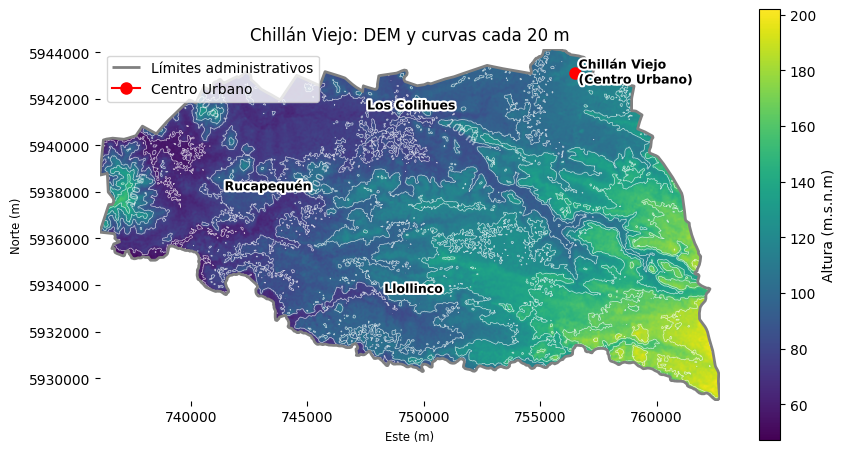

In [11]:
dem_c = np.ma.masked_invalid(dem_comuna.values)
x0, y0, x1, y1 = dem_comuna.rio.bounds()
ext = (x0, x1, y0, y1)

zmin, zmax = np.nanmin(dem_comuna.values), np.nanmax(dem_comuna.values)
niveles = np.arange(np.ceil(zmin / INTERVALO_COMUNA_M) * INTERVALO_COMUNA_M, zmax, INTERVALO_COMUNA_M)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(dem_c, cmap="viridis", extent=ext, origin="upper")
cs = ax.contour(dem_c, levels=niveles, extent=ext, origin="upper", colors="white", linewidths=0.5, alpha=0.7)
maestras = [l for l in niveles if l % (5 * INTERVALO_COMUNA_M) == 0]
ax.clabel(cs, levels=maestras, fontsize=8, fmt="%.0f m")
comuna_utm.boundary.plot(ax=ax, color="gray", linewidth=2, label="Límites administrativos")
fig.colorbar(im, ax=ax, label="Altura (m.s.n.m)", shrink=0.7)

# 1. Coordenadas UTM y anotación para el Centro Urbano de Chillán Viejo
urban_x = 756495
urban_y = 5943127
ax.plot(urban_x, urban_y, marker="o", color="red", markersize=8, label="Centro Urbano")
ax.text(urban_x + 150, urban_y, "Chillán Viejo\n(Centro Urbano)", fontsize=9, color="black",
        fontweight="bold", va="center", ha="left",
        path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

# 2. Coordenadas UTM y anotación para Los Colihues (sin icono marcador)
target_colihues_x = 749444
target_colihues_y = 5941693
ax.text(target_colihues_x, target_colihues_y, "Los Colihues", fontsize=9, color="black",
        fontweight="bold", va="center", ha="center",
        path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

# 4. Coordenadas UTM y anotación para Rucapequén (sin icono marcador)
rucapequen_x = 743304
rucapequen_y = 5938219
ax.text(rucapequen_x, rucapequen_y, "Rucapequén", fontsize=9, color="black",
        fontweight="bold", va="center", ha="center",
        path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

# 5. Coordenadas UTM y anotación para Llollinco (sin icono marcador)
llollinco_x = 749538
llollinco_y = 5933813
ax.text(llollinco_x, llollinco_y, "Llollinco", fontsize=9, color="black",
        fontweight="bold", va="center", ha="center",
        path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

# Centrar el mapa recortando los límites estrictamente a la comuna de Chillán Viejo
xmin, ymin, xmax, ymax = comuna_utm.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Añadir los ejes X e Y con etiquetas legibles y formato plano
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")
ax.ticklabel_format(useOffset=False, style="plain")

# Eliminar únicamente el recuadro negro exterior (espinas) manteniendo las etiquetas de los ejes
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(f"Chillán Viejo: DEM y curvas cada {INTERVALO_COMUNA_M} m")
ax.legend(loc="upper left")
plt.show()

## 5. Procesamiento a Nivel de Predio

> **Nota de advertencia -> Limitaciones a escala predial**
>
> La generación de curvas de nivel con intervalos reducidos (ej. 1 m o 2 m) a partir del DEM ALOS PALSAR, cuya resolución espacial es de 12.5 m por píxel y error vertical de  $\pm 2 a \pm 5$ m, introduce una **falsa precisión altimétrica**. A nivel predial, un solo píxel promedia un área de $156.25\text{ m}^2$, omitiendo elementos microtopográficos críticos como taludes, zanjas o pequeñas variaciones del terreno. Interpolar curvas a intervalos menores que la precisión vertical del sensor no genera información real, sino superficies suavizadas matemáticamente que distorsionan la geometría local del predio.
>
> El uso de estas curvas para la toma de decisiones a escala predial implica riesgos operacionales significativos, especialmente en el cálculo de movimientos de tierra, el diseño de obras de drenaje y la determinación de cotas de edificación. Para proyectos que requieran intervalos de curvas menores a 5 m a nivel de parcela, es indispensable sustituir este producto por fuentes de alta resolución espacial y centimétrica, tales como levantamientos topográficos con fotogrametría UAV (drones), LiDAR o GNSS-RTK.

Continuando, para obtener curvas de nivel a intervalo de 1 metro dentro del area de un predio, se aplica:
* **Buffer de seguridad** para evitar efectos de borde en el recorte.
* **Filtro Gaussiano normalizado** para suavizar el terreno ignorando de forma segura las celdas sin datos (`NaN`).
* **Extracción de curvas con GDAL** (`gdal_contour`) y recorte final exacto al límite de la propiedad.

In [12]:
def suavizar_gauss_nan(a: np.ndarray, sigma_px: float) -> np.ndarray:
    """Filtro Gaussiano que ignora NaN (convolución normalizada)."""
    valido = np.isfinite(a)
    num = ndi.gaussian_filter(np.where(valido, a, 0.0), sigma_px)
    den = ndi.gaussian_filter(valido.astype(float), sigma_px)
    return np.where(valido & (den > 1e-6), num / np.maximum(den, 1e-6), np.nan)


def generar_curvas(tif: Path, gpkg: Path, intervalo: float) -> gpd.GeoDataFrame:
    gpkg.unlink(missing_ok=True)
    subprocess.run(["gdal_contour", "-f", "GPKG", "-a", "ELEV", "-i", str(intervalo), str(tif), str(gpkg)],
                   check=True)
    return gpd.read_file(gpkg)

In [13]:
predio = gpd.read_file(RUTA_KML_PREDIO)                     # pyogrio lee KML sin ajustes adicionales
crs_predio = predio.estimate_utm_crs()
predio_utm = predio.to_crs(crs_predio)

caja = predio_utm.buffer(BUFFER_PREDIO_M).to_crs(xds.rio.crs).total_bounds
dem_predio = (xds.rio.clip_box(*caja)
                 .rio.reproject(crs_predio, resolution=RES_M, resampling=Resampling.bilinear))

sigma_px = SIGMA_SUAVIZADO_M / RES_M
dem_suave = dem_predio.copy(data=suavizar_gauss_nan(dem_predio.values, sigma_px))

ruta_tif = CARPETA_SALIDA / "dem_predio_colihue_utm_suave.tif"
dem_suave.rio.to_raster(ruta_tif, compress="DEFLATE")
print(f"✔ DEM suavizado del predio exportado exitosamente en: {ruta_tif}")

ruta_gpkg = CARPETA_SALIDA / f"curvas_nivel_colihue_{INTERVALO_PREDIO_M}m.gpkg"
curvas = generar_curvas(ruta_tif, ruta_gpkg, INTERVALO_PREDIO_M)
print(f"✔ Archivo base de curvas de nivel generado en: {ruta_gpkg}")

curvas = gpd.clip(curvas, predio_utm)                    # corta al límite exacto del predio
ruta_curvaspredio = CARPETA_SALIDA / f"clip_predio_curvas_colihue_{INTERVALO_PREDIO_M}m.gpkg"
curvas.to_file(ruta_curvaspredio, driver="GPKG")
print(f"✔ Curvas de nivel recortadas al límite del predio exportadas en: {ruta_curvaspredio}")

# Definir como maestras las curvas múltiplos de la constante centralizada (ej. cada 5 metros)
curvas["maestra"] = (curvas["ELEV"] % INTERVALO_MAESTRAS_PREDIO_M) == 0

z = dem_predio.values[np.isfinite(dem_predio.values)]
print(f"Relieve en el área (con buffer): {z.min():.0f}–{z.max():.0f} m | {len(curvas)} curvas | CRS {curvas.crs}")

✔ DEM suavizado del predio exportado exitosamente en: /content/drive/MyDrive/output/dem_predio_colihue_utm_suave.tif
✔ Archivo base de curvas de nivel generado en: /content/drive/MyDrive/output/curvas_nivel_colihue_1m.gpkg
✔ Curvas de nivel recortadas al límite del predio exportadas en: /content/drive/MyDrive/output/clip_predio_curvas_colihue_1m.gpkg
Relieve en el área (con buffer): 66–87 m | 44 curvas | CRS EPSG:32718


### Visualización a nivel predial

Presentamos el mapa final del predio combinando:
* Curvas de nivel coloreadas por su elevación.
* Etiquetas de elevación con efecto de halo para máxima legibilidad.
* Un mapa base satelital provisto por **Esri World Imagery** de fondo.

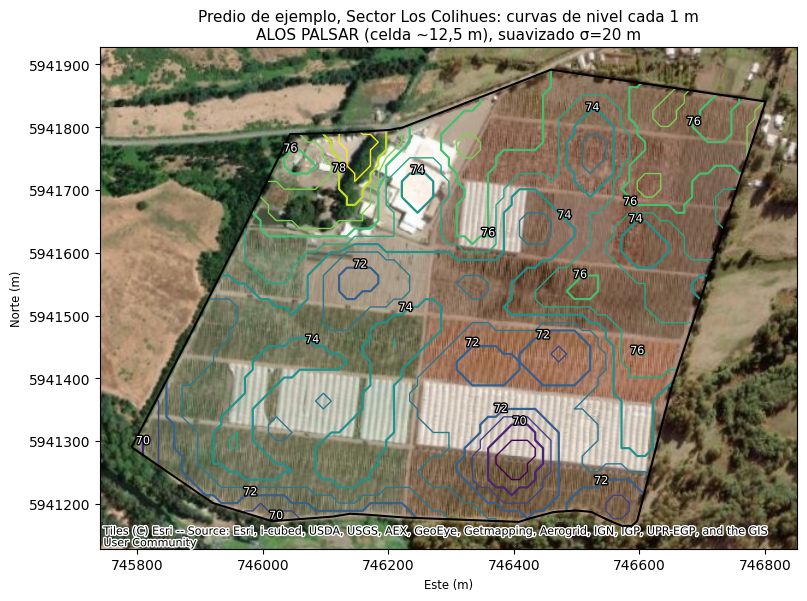

In [14]:
fig, ax = plt.subplots(figsize=(9, 8))
halo = [pe.withStroke(linewidth=2.8, foreground="black")]
vmin, vmax = curvas["ELEV"].min(), curvas["ELEV"].max()

curvas[~curvas.maestra].plot(
    ax=ax, column="ELEV", cmap="viridis", vmin=vmin, vmax=vmax,
    linewidth=1, zorder=2
)
curvas[curvas.maestra].plot(
    ax=ax, column="ELEV", cmap="viridis", vmin=vmin, vmax=vmax,
    linewidth=1.6, zorder=3
)
predio_utm.boundary.plot(ax=ax, color="black", linewidth=1.5, zorder=4)

# etiquetas solo en curvas maestras (pocas líneas)
for geom, elev in zip(curvas[curvas.maestra].geometry, curvas[curvas.maestra].ELEV):
    partes = geom.geoms if geom.geom_type == "MultiLineString" else [geom]
    mayor = max(partes, key=lambda g: g.length)
    p = mayor.interpolate(0.5, normalized=True)
    ax.annotate(f"{elev:.0f}", (p.x, p.y), fontsize=8, color="white", ha="center",
                path_effects=[pe.withStroke(linewidth=2, foreground="black")], zorder=5)

cx.add_basemap(ax, crs=curvas.crs, source=cx.providers.Esri.WorldImagery)
ax.ticklabel_format(useOffset=False, style="plain")
ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
ax.set_title(f"Predio de ejemplo, Sector Los Colihues: curvas de nivel cada {INTERVALO_PREDIO_M} m\n"
             f"ALOS PALSAR (celda ~12,5 m), suavizado σ={SIGMA_SUAVIZADO_M} m", fontsize=11)
plt.show()

## 6. Síntesis conceptual

El procesamiento de Modelos Digitales de Elevación constituye una aplicación relevante de la ciencia de datos geoespaciales, debido a que permite transformar información altimétrica en productos cartográficos y analíticos mediante procedimientos computacionales. La generación de curvas de nivel representa una de las principales aplicaciones de estos modelos, permitiendo interpretar la distribución espacial de las elevaciones y reconocer características generales del relieve.

El flujo de trabajo desarrollado en el notebook integra adquisición de datos, exploración de metadatos, reproyección, remuestreo, recorte espacial, suavizado Gaussiano y extracción de curvas de nivel mediante Python y GDAL.

La aplicación a escala regional ofrece una visión macro del comportamiento del territorio y sus grandes unidades morfológicas; la escala comunal permite obtener una representación general del relieve local; mientras que el procesamiento predial facilita una visualización espacialmente delimitada de las variaciones altimétricas específicas.

Sin embargo, la interpretación de los resultados exige distinguir entre resolución espacial, precisión vertical y nivel de detalle cartográfico. La generación de curvas con intervalos pequeños no implica necesariamente una mayor precisión del terreno representado. Esto se debe a que el nivel de detalle utilizable en una escala predial está intrínsecamente limitado por la resolución espacial del Modelo Digital de Elevación (MDE) de origen y el Error Medio Cuadrático (RMSE) de sus datos base.

Cuando se fuerzan intervalos de isolíneas menores que la resolución del MDE o que la incertidumbre vertical del sensor, el proceso de interpolación simplemente reescribe o suaviza matemáticamente la misma malla de datos base. Lejos de aportar información morfológica nueva, esta práctica genera una falsa sensación de precisión (artesanía o ruido cartográfico), donde la densidad de líneas representa artefactos geométricos propios del algoritmo de interpolación y no microtopografía real del terreno. En consecuencia, si la densidad de puntos o el tamaño del píxel del modelo de origen —diseñado conceptualmente para coberturas regionales o comunales— no captura variaciones a métrica predial, subdividir los intervalos altimétricos solo sobresatura la representación cartográfica sin incrementar la exactitud topográfica real.